# Perfiles de vulnerabilidad con PCA y K-Means

En este notebook agrupamos a las personas de la encuesta ASP 2022 en perfiles de vulnerabilidad. Los pasos son:

- Seleccionar y transformar las variables
- Escalar los datos
- Reducir la dimensión con PCA
- Elegir el número de clusters con el coeficiente de silhouette
- Entrenar K-Means y describir cada perfil

In [1]:
#importar librerias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/anaconda3/lib/python3.12/site-

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.5.4 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



In [2]:
#cargamos el dataset
df = pd.read_csv("asp_2022_variables_limpio.csv")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (3003, 50)


,id_persona,factor_expansion,localidad,edad,sexo_nacimiento,orientacion_sexual,identidad_genero,estado_civil,autoreconocimiento_etnico,pais_nacimiento,...,vacuna_vph,citologia_ultimo_anio,discriminacion_general,discriminacion_personal_salud,amenazas_recibidas,amenaza_personal_salud,forzada_relaciones_sexuales,forzada_por_personal_salud,denuncio_hecho,violencia_fuerza_publica
0,1501001,1.428571,Antonio Nariño,19,Mujer,Bisexual,Femenina,Soltero(a),Ninguno,Colombia,...,Sí,Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
1,1501002,1.428571,Antonio Nariño,26,Hombre,Heterosexual,Femenina,Soltero(a),Ninguno,Venezuela,...,No aplica (no se hizo la pregunta),Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
2,1501003,1.428571,Antonio Nariño,21,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,Venezuela,...,No,Sí,No,No aplica (no se hizo la pregunta),Sí,No,Sí,No,No,Sí
3,1501004,1.428571,Antonio Nariño,20,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,Colombia,...,Sí,Sí,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No
4,1501005,1.428571,Antonio Nariño,20,Mujer,Heterosexual,Femenina,Soltero(a),Ninguno,Venezuela,...,No,No,No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No,No aplica (no se hizo la pregunta),No aplica (no se hizo la pregunta),No


# Selección de variables

No todas las columnas sirven para el K-Means:

- `id_persona` es solo un identificador.
- `factor_expansion` no describe a la persona; lo guardamos para ponderar los resultados al final.
- Las preguntas con **"No aplica"** (barreras en salud, régimen, denuncias, etc.) solo se le hicieron a una parte de las personas. Si las usamos, K-Means agruparía según a quién le hicieron la pregunta.
- `vive_permanente_bogota`, `actividad_principal` y `sabe_leer_escribir` tienen más del 90 % en una sola respuesta, así que casi no aportan información.
- `afiliado_seg_social_salud` **no entra** al modelo: es la variable que queremos explicar después. La usamos al final para ver si los perfiles tienen diferente nivel de afiliación.

In [3]:
#variables que usaremos para formar los clusters
variables = ["edad", "personas_hogar", "dependientes_economicos", "autopercepcion_nivel_economico",
             "horas_semana_asp", "edad_inicio_asp", "tiempo_viviendo_bogota", "nivel_educativo",
             "tipo_vivienda", "pais_nacimiento", "autoreconocimiento_etnico", "victima_conflicto_armado",
             "ingresos_suficientes_gastos", "paga_intermediario_tercero", "discriminacion_general",
             "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]

datos = df[variables].copy()
print("Número de variables:", len(variables))

Número de variables: 18


# Transformación de variables

K-Means solo trabaja con números, así que convertimos las respuestas de texto:

- **Ordinales** (tienen un orden): tiempo en Bogotá, nivel educativo y tipo de vivienda pasan a una escala numérica.
- **Sí / No**: pasan a 1 y 0.
- **No sabe/No responde** es menos del 1 % en cada variable, así que lo reemplazamos por la respuesta más frecuente (la moda).

In [4]:
#reemplazamos "No sabe/No responde" por la moda de cada columna
for col in datos.columns:
    if datos[col].dtype != "int64" and datos[col].dtype != "float64":
        moda = datos[col][datos[col] != "No sabe/No responde"].mode()[0]
        datos[col] = datos[col].replace("No sabe/No responde", moda)

In [5]:
#variables ordinales a escala numérica
tiempo = {"Menos de 1 año": 0, "Entre 1 y 5 años": 1, "Entre 6 y 10 años": 2, "Más de 10 años": 3}

educacion = {"Ninguno": 0, "Preescolar": 0, "Básica primaria": 1, "Básica secundaria": 2,
             "Media": 3, "Técnico": 4, "Tecnológico": 4, "Universitario": 5,
             "Especialización": 6, "Doctorado": 6}

#tipo de vivienda: 0 = casa o apartamento, 1 = cuarto en vivienda, 2 = cuarto en hotel o establecimiento
vivienda = {"Casa": 0, "Apartamento": 0, "Otro tipo de vivienda": 0,
            "Cuarto en estructura tipo vivienda": 1,
            "Cuarto en hotel": 2, "Cuarto en el establecimiento de ASP": 2}

datos["tiempo_viviendo_bogota"] = datos["tiempo_viviendo_bogota"].map(tiempo)
datos["nivel_educativo"] = datos["nivel_educativo"].map(educacion)
datos["tipo_vivienda"] = datos["tipo_vivienda"].map(vivienda)

In [6]:
#variables de dos categorías a 1 y 0
datos["pais_nacimiento"] = (datos["pais_nacimiento"] != "Colombia").astype(int)                    #1 = migrante
datos["autoreconocimiento_etnico"] = (datos["autoreconocimiento_etnico"] != "Ninguno").astype(int)  #1 = pertenece a un grupo étnico
datos["ingresos_suficientes_gastos"] = (datos["ingresos_suficientes_gastos"] == "No").astype(int)  #1 = ingresos NO alcanzan

si_no = ["victima_conflicto_armado", "paga_intermediario_tercero", "discriminacion_general",
         "amenazas_recibidas", "forzada_relaciones_sexuales", "violencia_fuerza_publica"]
for col in si_no:
    datos[col] = (datos[col] == "Sí").astype(int)

#renombramos para que el significado del 1 sea claro
datos = datos.rename(columns={"pais_nacimiento": "migrante",
                              "autoreconocimiento_etnico": "grupo_etnico",
                              "ingresos_suficientes_gastos": "ingresos_insuficientes"})
datos.head()

,edad,personas_hogar,dependientes_economicos,autopercepcion_nivel_economico,horas_semana_asp,edad_inicio_asp,tiempo_viviendo_bogota,nivel_educativo,tipo_vivienda,migrante,grupo_etnico,victima_conflicto_armado,ingresos_insuficientes,paga_intermediario_tercero,discriminacion_general,amenazas_recibidas,forzada_relaciones_sexuales,violencia_fuerza_publica
0,19,1,0,5,48,18,0,4,0,0,0,0,1,1,0,0,0,0
1,26,1,2,4,48,26,1,5,1,1,0,0,1,1,0,0,0,0
2,21,7,4,5,48,21,1,2,0,1,0,0,1,1,0,1,1,1
3,20,2,0,1,42,16,0,3,2,0,0,0,0,0,0,0,0,0
4,20,1,4,1,56,16,0,2,2,1,0,0,1,0,0,0,0,0


In [7]:
#revisamos que no queden valores vacíos
datos.isnull().sum().sum()

np.int64(0)

# Escalado de los datos

Las variables tienen escalas muy distintas (la edad va de 18 a 77 y las variables Sí/No van de 0 a 1). Usamos `StandardScaler`, que deja cada variable con media 0 y desviación estándar 1. Es el escalado que necesita PCA: así ninguna variable pesa más solo por tener números más grandes.

In [8]:
#escalado de los datos con StandardScaler
escalador = StandardScaler().fit(datos.values)

datos_escalados = pd.DataFrame(escalador.transform(datos.values),
                               columns=datos.columns)
datos_escalados.head()

,edad,personas_hogar,dependientes_economicos,autopercepcion_nivel_economico,horas_semana_asp,edad_inicio_asp,tiempo_viviendo_bogota,nivel_educativo,tipo_vivienda,migrante,grupo_etnico,victima_conflicto_armado,ingresos_insuficientes,paga_intermediario_tercero,discriminacion_general,amenazas_recibidas,forzada_relaciones_sexuales,violencia_fuerza_publica
0,-1.187097,-0.919457,-1.265793,0.867506,0.036388,-0.606938,-1.520125,1.134183,-0.958236,-0.868383,-0.440495,-0.395391,0.620603,1.728597,-0.826047,-0.395954,-0.360273,-0.359683
1,-0.536101,-0.919457,-0.093856,0.310380,0.036388,0.528041,-0.638693,1.956082,0.176457,1.151566,-0.440495,-0.395391,0.620603,1.728597,-0.826047,-0.395954,-0.360273,-0.359683
2,-1.001098,2.882879,1.078080,0.867506,0.036388,-0.181321,-0.638693,-0.509616,-0.958236,1.151566,-0.440495,-0.395391,0.620603,1.728597,-0.826047,2.525545,2.775671,2.780225
3,-1.094097,-0.285734,-1.265793,-1.360997,-0.252058,-0.890683,-1.520125,0.312283,1.311150,-0.868383,-0.440495,-0.395391,-1.611337,-0.578504,-0.826047,-0.395954,-0.360273,-0.359683
4,-1.094097,-0.919457,1.078080,-1.360997,0.420983,-0.890683,-1.520125,-0.509616,1.311150,1.151566,-0.440495,-0.395391,0.620603,-0.578504,-0.826047,-0.395954,-0.360273,-0.359683


# PCA

PCA resume las 18 variables en pocas **componentes principales** que guardan la mayor parte de la información. Nos quedamos con las componentes necesarias para conservar alrededor del 65 % de la varianza.

In [9]:
#calculamos PCA con todas las componentes para ver cuánta varianza explica cada una
pca = PCA().fit(datos_escalados)
varianza_acumulada = np.cumsum(pca.explained_variance_ratio_)

for i, v in enumerate(varianza_acumulada):
    print("Componentes:", i + 1, " Varianza acumulada: %0.2f" % v)

Componentes: 1  Varianza acumulada: 0.16
Componentes: 2  Varianza acumulada: 0.26
Componentes: 3  Varianza acumulada: 0.35
Componentes: 4  Varianza acumulada: 0.43
Componentes: 5  Varianza acumulada: 0.49
Componentes: 6  Varianza acumulada: 0.55
Componentes: 7  Varianza acumulada: 0.60
Componentes: 8  Varianza acumulada: 0.66
Componentes: 9  Varianza acumulada: 0.70
Componentes: 10  Varianza acumulada: 0.75
Componentes: 11  Varianza acumulada: 0.79
Componentes: 12  Varianza acumulada: 0.83
Componentes: 13  Varianza acumulada: 0.87
Componentes: 14  Varianza acumulada: 0.91
Componentes: 15  Varianza acumulada: 0.94
Componentes: 16  Varianza acumulada: 0.97
Componentes: 17  Varianza acumulada: 0.98
Componentes: 18  Varianza acumulada: 1.00


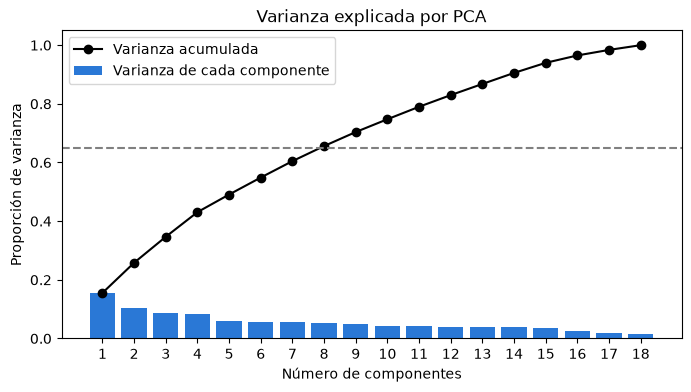

In [10]:
#gráfica de la varianza acumulada
componentes = range(1, len(varianza_acumulada) + 1)

plt.figure(figsize=(8, 4), dpi=100)
plt.bar(componentes, pca.explained_variance_ratio_, color="#2a78d6", label="Varianza de cada componente")
plt.plot(componentes, varianza_acumulada, marker="o", color="black", label="Varianza acumulada")
plt.axhline(0.65, color="gray", linestyle="--")
plt.xlabel("Número de componentes")
plt.ylabel("Proporción de varianza")
plt.title("Varianza explicada por PCA")
plt.xticks(componentes)
plt.legend()
plt.show()

In [11]:
#elegimos el número de componentes que alcanza el 65 % de la varianza
n_componentes = np.argmax(varianza_acumulada >= 0.65) + 1
print("Componentes elegidas:", n_componentes)

pca = PCA(n_components=n_componentes)
datos_pca = pca.fit_transform(datos_escalados)

datos_pca = pd.DataFrame(datos_pca, columns=["PC" + str(i + 1) for i in range(n_componentes)])
datos_pca.head()

Componentes elegidas: 8


,PC1,PC2,PC3,PC4,PC5,PC6,PC7,PC8
0,1.421307,0.080620,-1.329060,-0.717228,0.231019,0.414860,1.277461,-0.342213
1,1.955100,0.343235,-0.003450,0.631898,-0.783255,0.561244,1.224403,-0.356418
2,0.319635,2.668109,2.782071,-3.373740,-0.123001,-1.597934,0.433071,-0.991496
3,0.866669,0.600038,-2.337273,0.706219,0.539235,-0.478738,-0.254665,-0.974262
4,1.312728,1.418485,-0.518491,2.115102,0.852197,-1.798533,-0.295924,0.163722


In [12]:
#variables que más pesan en las dos primeras componentes
cargas = pd.DataFrame(pca.components_.T, index=datos.columns,
                      columns=["PC" + str(i + 1) for i in range(n_componentes)])

print("PC1:\n", cargas["PC1"].sort_values(key=abs, ascending=False).head(4))
print("\nPC2:\n", cargas["PC2"].sort_values(key=abs, ascending=False).head(4))

PC1:
 migrante                    0.425822
tiempo_viviendo_bogota     -0.383942
edad                       -0.341448
violencia_fuerza_publica   -0.284876
Name: PC1, dtype: float64

PC2:
 amenazas_recibidas             0.376504
edad                          -0.334164
forzada_relaciones_sexuales    0.328649
tipo_vivienda                  0.324015
Name: PC2, dtype: float64


# Coeficiente de silhouette

El coeficiente de silhouette mide qué tan bien separados están los clusters. Va de -1 a 1: **mientras más alto, mejor**. Probamos K entre 2 y 7 y elegimos el mejor valor entre 3 y 5 perfiles.

K = 2  Silhouette = 0.167
K = 3  Silhouette = 0.168
K = 4  Silhouette = 0.133
K = 5  Silhouette = 0.132
K = 6  Silhouette = 0.137
K = 7  Silhouette = 0.133


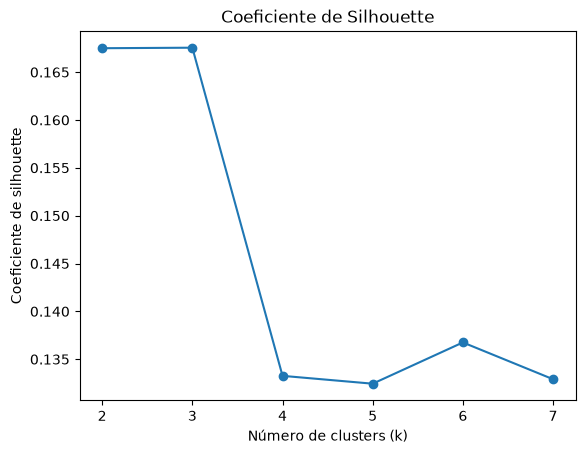

In [13]:
silhouette = []
K_range = range(2, 8)

for k in K_range:
    kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
    kmeans.fit(datos_pca.values)
    silhouette.append(silhouette_score(datos_pca.values, kmeans.labels_))
    print("K =", k, " Silhouette = %0.3f" % silhouette[-1])

#gráfica del coeficiente de silhouette
plt.plot(K_range, silhouette, marker="o")
plt.xlabel("Número de clusters (k)")
plt.ylabel("Coeficiente de silhouette")
plt.title("Coeficiente de Silhouette")
plt.show()

Entre 3 y 5 clusters, el valor más alto está en **K = 3**. El silhouette es bajo (cerca de 0,17), lo que significa que los perfiles se parecen un poco entre sí. Es normal en datos de encuestas, porque las condiciones de vida de las personas no se dividen en grupos totalmente separados.

# K-Means con K = 3

In [14]:
k = 3
kmeans = KMeans(n_clusters=k, random_state=42, n_init=10)
kmeans.fit(datos_pca.values)

#asignamos el cluster a cada persona
df["cluster"] = kmeans.labels_
datos["cluster"] = kmeans.labels_

print("Personas por cluster:\n", df["cluster"].value_counts().sort_index())
print("\nInercia: ", kmeans.inertia_)

Personas por cluster:
 cluster
0     451
1    1380
2    1172
Name: count, dtype: int64

Inercia:  26147.472511276632


# Gráfica de los clusters

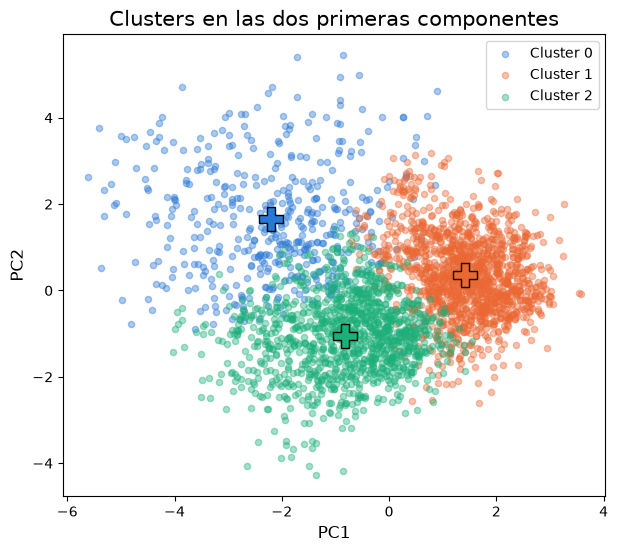

In [15]:
#graficamos sobre las dos primeras componentes (PC1 y PC2)
plt.figure(figsize=(7, 6), dpi=100)

colores = ["#2a78d6", "#eb6834", "#1baf7a", "black", "purple"]
for cluster in range(kmeans.n_clusters):
    plt.scatter(datos_pca[df["cluster"] == cluster]["PC1"],
                datos_pca[df["cluster"] == cluster]["PC2"],
                marker="o", s=20, color=colores[cluster], alpha=0.4, label="Cluster %i" % cluster)

    plt.scatter(kmeans.cluster_centers_[cluster][0],
                kmeans.cluster_centers_[cluster][1],
                marker="P", s=280, color=colores[cluster], edgecolor="black")

plt.title("Clusters en las dos primeras componentes", fontsize=15)
plt.xlabel("PC1", fontsize=12)
plt.ylabel("PC2", fontsize=12)
plt.legend()
plt.show()

# Perfiles de cada cluster

Calculamos el promedio de cada variable dentro de cada cluster. Usamos `factor_expansion` para que los resultados representen a toda la población y no solo a la muestra. En las variables 0/1 el promedio es una proporción: por ejemplo, 0,87 en `migrante` significa que el 87 % del cluster es migrante.

In [16]:
#agregamos la afiliación a salud (1 = NO afiliada) solo para describir los perfiles
datos["no_afiliada_salud"] = (df["afiliado_seg_social_salud"] == "No").astype(int)
datos["factor_expansion"] = df["factor_expansion"]

#promedio ponderado por cluster = suma(valor x peso) / suma(pesos)
columnas = datos.columns.drop(["cluster", "factor_expansion"])
datos_por_peso = datos[columnas].multiply(datos["factor_expansion"], axis=0)
datos_por_peso["cluster"] = datos["cluster"]

perfiles = datos_por_peso.groupby("cluster").sum().div(datos.groupby("cluster")["factor_expansion"].sum(), axis=0)

#porcentaje de la población que representa cada cluster
perfiles["porcentaje_poblacion"] = datos.groupby("cluster")["factor_expansion"].sum() / datos["factor_expansion"].sum() * 100

perfiles.T.round(2)

cluster,0,1,2
edad,33.61,26.66,36.04
personas_hogar,2.04,2.72,2.37
dependientes_economicos,2.14,2.75,1.70
autopercepcion_nivel_economico,3.09,3.86,3.28
horas_semana_asp,53.06,48.28,43.48
edad_inicio_asp,19.06,23.32,22.58
tiempo_viviendo_bogota,2.15,0.78,2.61
nivel_educativo,2.51,2.99,2.32
tipo_vivienda,1.13,0.86,0.65
migrante,0.15,0.87,0.01


In [17]:
#nombramos cada cluster según su tabla de perfiles
#OJO: si al ejecutar cambian los números de los clusters, revisa la tabla de arriba y ajusta este diccionario
nombres = {0: "Alta exposición a violencias",
           1: "Migrantes de llegada reciente",
           2: "Colombianas establecidas con precariedad económica"}

df["perfil"] = df["cluster"].map(nombres)
perfiles.index = perfiles.index.map(nombres)
perfiles[["porcentaje_poblacion", "migrante", "edad", "tiempo_viviendo_bogota",
          "ingresos_insuficientes", "amenazas_recibidas", "violencia_fuerza_publica", "no_afiliada_salud"]].T.round(2)

cluster,Alta exposición a violencias,Migrantes de llegada reciente,Colombianas establecidas con precariedad económica
porcentaje_poblacion,13.53,49.50,36.97
migrante,0.15,0.87,0.01
edad,33.61,26.66,36.04
tiempo_viviendo_bogota,2.15,0.78,2.61
ingresos_insuficientes,0.82,0.60,0.78
amenazas_recibidas,0.67,0.06,0.02
violencia_fuerza_publica,0.60,0.02,0.03
no_afiliada_salud,0.32,0.79,0.19


# Afiliación a salud por perfil

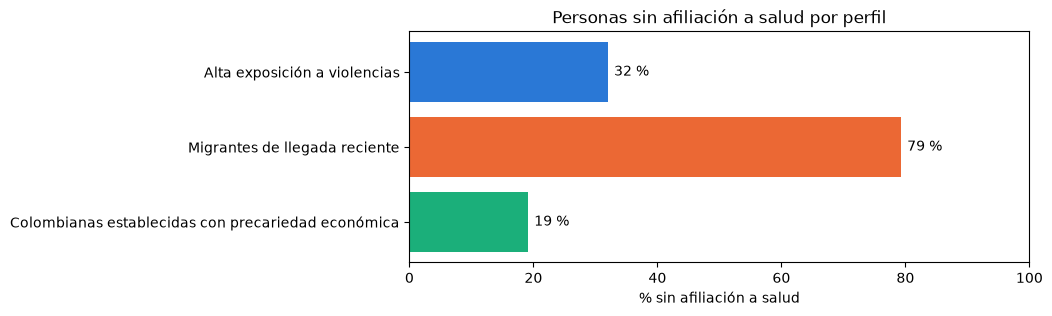

In [18]:
#porcentaje de personas SIN afiliación a salud en cada perfil
sin_afiliacion = perfiles["no_afiliada_salud"] * 100

plt.figure(figsize=(8, 3), dpi=100)
plt.barh(sin_afiliacion.index, sin_afiliacion.values, color=colores[:3])
for i, v in enumerate(sin_afiliacion.values):
    plt.text(v + 1, i, "%0.0f %%" % v, va="center")
plt.xlim(0, 100)
plt.xlabel("% sin afiliación a salud")
plt.title("Personas sin afiliación a salud por perfil")
plt.gca().invert_yaxis()
plt.show()

# Conclusiones

Con PCA (8 componentes, cerca del 66 % de la varianza) y K-Means con K = 3 encontramos tres perfiles:

- **Migrantes de llegada reciente (≈ 50 % de la población).** La mayoría nació fuera de Colombia y lleva poco tiempo en Bogotá. Son más jóvenes y tienen más personas a cargo. Casi **8 de cada 10 no tienen afiliación a salud**.
- **Colombianas establecidas con precariedad económica (≈ 37 %).** Llevan muchos años en Bogotá, son mayores y la mayoría dice que sus ingresos no alcanzan. Es el perfil con **mejor cobertura en salud**: solo cerca del 19 % no está afiliada.
- **Alta exposición a violencias (≈ 14 %).** Tienen las tasas más altas de amenazas, violencia sexual, violencia de la fuerza pública y discriminación. Empezaron la actividad más jóvenes y trabajan más horas a la semana. Cerca del 32 % no está afiliada.

La afiliación a salud no se usó para formar los clusters y aun así cambia mucho entre perfiles. Eso muestra que la segmentación sirve para la pregunta del proyecto: **la condición migratoria es el factor que más se relaciona con no tener salud**.

# Guardar resultados

In [ ]:
#guardamos el perfil asignado a cada persona y la tabla de perfiles
df[["id_persona", "factor_expansion", "localidad", "cluster", "perfil"]].to_csv("asp_perfiles_kmeans.csv", index=False)
perfiles.round(3).to_csv("perfiles_ponderados.csv")